# Symmetric NMR tensor validation

Run 01-SymmetricTensor-Scratch-N100-9245885. Validation review, 4 November 2026.

In [1]:
run_id = '01-SymmetricTensor-Scratch-N100-9245885'

from pathlib import Path
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph
from graph_pes.config.shared import instantiate_config_from_dict, parse_loss
from graph_pes.config.training import TrainingConfig

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'nmr_helpers').is_dir())
sys.path.insert(0, str(root))
import nmr_helpers  # Register custom models and losses.

torch.set_num_threads(2)
torch.set_default_dtype(torch.float32)
run = root / 'graph-pes-results' / run_id
config = yaml.safe_load((run / 'train-config.yaml').read_text())
valid = config['data']['valid']
frames = read(root / valid['path'], index=':')
assert len(frames) == 50

def load(path):
    return torch.load(path, map_location='cpu', weights_only=False)

model = load(run / 'model.pt').eval()
ckpts = {name: load(run / 'checkpoints' / f'{name}.ckpt') for name in ('best', 'last')}
states = {name: {key[6:]: value for key, value in ckpt['state_dict'].items()
                 if key.startswith('model.')} for name, ckpt in ckpts.items()}
assert model.state_dict().keys() == states['best'].keys()
for key, value in model.state_dict().items():
    if torch.is_tensor(value):
        torch.testing.assert_close(value, states['best'][key], rtol=0, atol=0)

stop = next(value for key, value in ckpts['last']['callbacks'].items()
            if key.startswith('EarlyStopping'))
improvements = np.array([float(value) for value in re.findall(
    r'New best model: validation loss ([0-9.eE+-]+)', (run/'rank-0.log').read_text())])
assert np.isclose(improvements[-1], stop['best_val_loss'])
lr = ckpts['last']['optimizer_states'][0]['param_groups'][0]['lr']
print(f"Validation: {valid['path']}, {len(frames)} structures, {sum(map(len, frames)):,} atoms.")
print(f"Final learning rate: {lr:.6g}. Checks since best: {stop['wait_count']}/{stop['patience']}.")
print("Exported model tensor state matches best.ckpt exactly.")

Validation: data/nmr_symm/valid.xyz, 50 structures, 7,200 atoms.
Final learning rate: 0.000206158. Checks since best: 300/300.
Exported model tensor state matches best.ckpt exactly.


In [2]:
mapping = valid['property_map']
graphs = [AtomicGraph.from_ase(atoms, cutoff=float(model.cutoff), property_mapping=mapping)
          for atoms in frames]
properties = list(mapping.values())
_, fit_config = instantiate_config_from_dict(config, TrainingConfig)
loss_fn = parse_loss(fit_config.loss)
predictions, losses = {}, {}
for name, state in states.items():
    model.load_state_dict(state, strict=True)
    predictions[name] = {key: [] for key in properties}
    frame_losses = []
    for graph in graphs:
        # Force prediction differentiates energy with respect to positions.
        with torch.set_grad_enabled('forces' in properties):
            predicted = model.predict(graph, properties)
        for key, tensor in predicted.items():
            assert torch.isfinite(tensor).all()
            assert tensor.shape == graph.properties[key].shape
            predictions[name][key].append(tensor.detach().cpu().numpy())
        with torch.no_grad():
            frame_losses.append(float(loss_fn(model, graph, predicted).loss_value))
    losses[name] = float(np.mean(frame_losses))

checkpoint_table = pd.DataFrame([
    {'Checkpoint': name, 'Epoch (1-based)': ckpt['epoch'] + 1,
     'Optimiser updates': ckpt['global_step'], 'Validation loss (CPU)': losses[name]}
    for name, ckpt in ckpts.items()
])
print(checkpoint_table.to_string(index=False, float_format=lambda x: f'{x:.6f}'))
gap = 100 * abs(losses['best'] / stop['best_val_loss'] - 1)
print(f"Best loss recorded on ARC: {stop['best_val_loss']:.6f}. CPU difference: {gap:.3f}%.")

Checkpoint  Epoch (1-based)  Optimiser updates  Validation loss (CPU)
      best              109               2725               0.041853
      last              409              10225               0.050515
Best loss recorded on ARC: 0.041853. CPU difference: 0.000%.


## Training progress

The best checkpoint was at epoch 109. Early stopping ended training at epoch 409, after 300 validation checks without improvement. The final learning rate was 0.000206. Validation loss was 20.7% higher at the final checkpoint. Use the best checkpoint as the scratch baseline.

The copied log lists new validation minima without epoch numbers. The plot counts these improvements. The checkpoint table gives the known epochs.

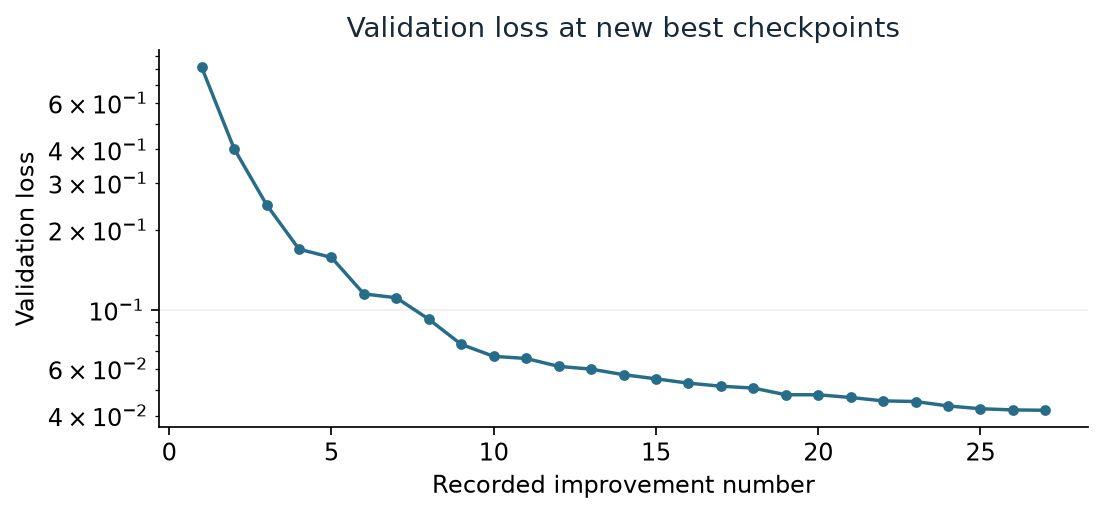

In [3]:
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'text.color': '#172839'})
fig, ax = plt.subplots(figsize=(7, 3.2), layout='constrained')
ax.plot(np.arange(1, len(improvements) + 1), improvements, 'o-', ms=4, lw=1.6, color='#276d89')
ax.set(yscale='log', xlabel='Recorded improvement number',
       ylabel='Validation loss', title='Validation loss at new best checkpoints')
ax.grid(axis='y', alpha=0.22)
plt.show()

## Validation parity

The isotropic shielding equals the scalar coefficient divided by √3. Anisotropic parity pools the five signed 2e coefficients in the stored e3nn basis separately for Si and O. Each component has equal weight. The anisotropic panels share axis limits. Each isotropic panel uses its element’s range. R² is 1 − SSE/SST over the reference values in each panel.

In [4]:
from e3nn.io import CartesianTensor

atomic_numbers = np.concatenate([a.numbers for a in frames])
target = np.concatenate([a.arrays['MS_Symm_Irreps'] for a in frames]).astype(np.float64)
# Check the basis and component order against the stored Cartesian tensors.
cartesian = CartesianTensor('ij=ji').to_cartesian(torch.from_numpy(target).float()).numpy()
reference = np.concatenate([a.arrays['MS_Symm_QM'].reshape(-1, 3, 3) for a in frames])
np.testing.assert_allclose(cartesian, reference, rtol=1e-6, atol=8e-5)

def panel_data(name):
    predicted = np.concatenate(predictions[name]['tensor']).astype(np.float64)
    panels = []
    for element, atomic_number in [('Si', 14), ('O', 8)]:
        mask = atomic_numbers == atomic_number
        panels.append((f'{element} isotropic shielding', 'ppm',
                       target[mask, 0] / np.sqrt(3), predicted[mask, 0] / np.sqrt(3)))
        panels.append((f'{element} anisotropic coefficients', 'ppm',
                       target[mask, 1:].ravel(), predicted[mask, 1:].ravel()))
    return panels

def metrics(reference, prediction):
    residual = prediction - reference
    return {'N': reference.size, 'RMSE': np.sqrt(np.mean(residual**2)),
            'MAE': np.mean(np.abs(residual)),
            'R²': 1 - np.sum(residual**2) / np.sum((reference - reference.mean())**2)}

records = [{'Checkpoint': name, 'Quantity': title, 'Units': units, **metrics(reference, prediction)}
           for name in ckpts for title, units, reference, prediction in panel_data(name)]
print(pd.DataFrame(records).to_string(index=False, float_format=lambda x: f'{x:.4f}'))

Checkpoint                    Quantity Units     N   RMSE    MAE     R²
      best      Si isotropic shielding   ppm  2400 2.0601 0.8810 0.9483
      best Si anisotropic coefficients   ppm 12000 3.4737 1.8677 0.9634
      best       O isotropic shielding   ppm  4800 3.9233 1.9615 0.9649
      best  O anisotropic coefficients   ppm 24000 5.1026 2.7687 0.9669
      last      Si isotropic shielding   ppm  2400 2.2672 0.9250 0.9374
      last Si anisotropic coefficients   ppm 12000 4.0185 2.1246 0.9510
      last       O isotropic shielding   ppm  4800 4.0884 1.9832 0.9619
      last  O anisotropic coefficients   ppm 24000 5.6018 3.0345 0.9601


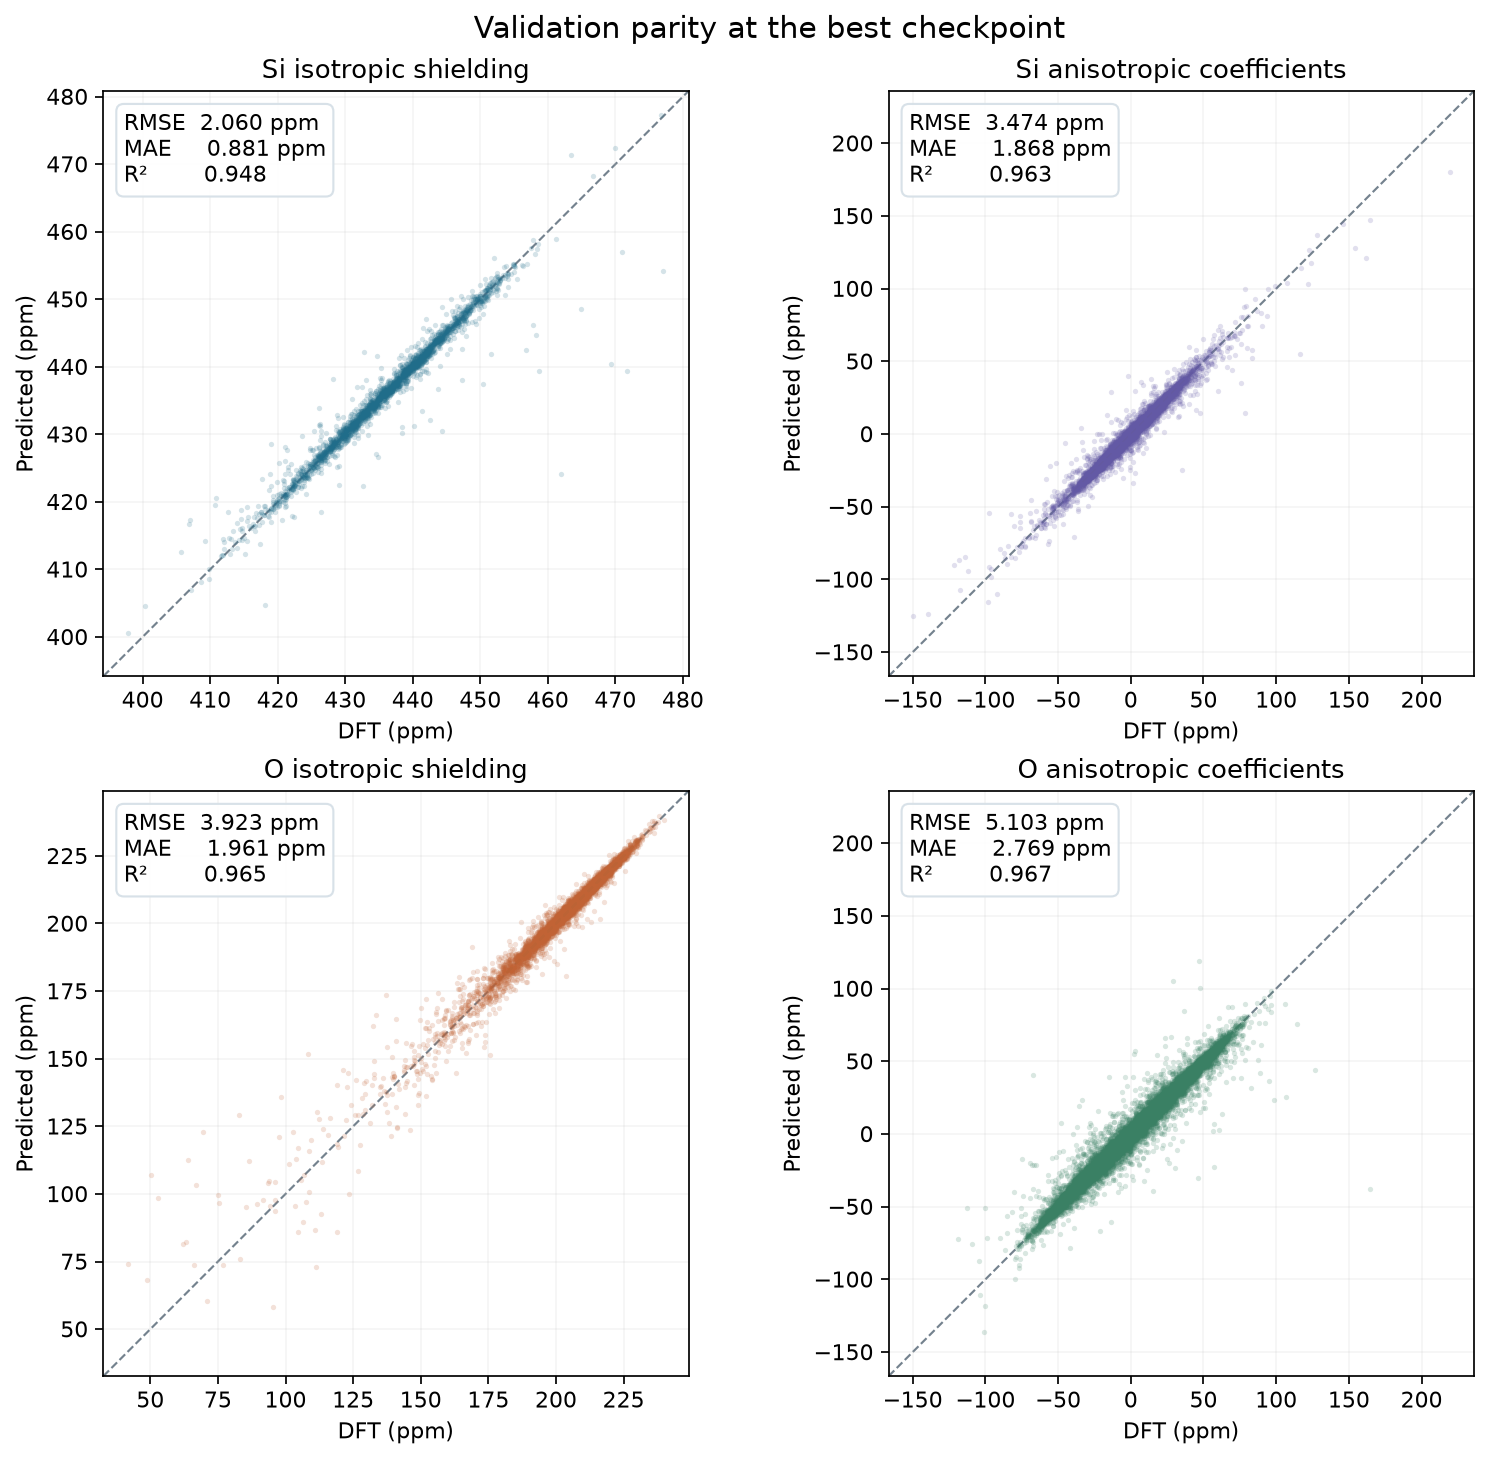

In [5]:
panels = panel_data('best')
nrows = len(panels) // 2
fig, axes = plt.subplots(nrows, 2, figsize=(10, 4.65 * nrows), squeeze=False, layout='constrained')
colors = ['#206d8a', '#6359a5', '#c16335', '#3a8064']
for idx, (ax, (title, units, reference, predicted)) in enumerate(zip(axes.flat, panels)):
    paired = [panels[idx % 2], panels[idx % 2 + 2]] if nrows == 2 and idx % 2 == 1 else [panels[idx]]
    low = min(min(p[2].min(), p[3].min()) for p in paired)
    high = max(max(p[2].max(), p[3].max()) for p in paired)
    pad = 0.045 * (high - low)
    limits = (low - pad, high + pad)
    ax.plot(limits, limits, '--', lw=1, color='#74828e', zorder=1)
    ax.scatter(reference, predicted, s=18 if reference.size <= 50 else 6,
               alpha=0.78 if reference.size <= 50 else 0.19,
               color=colors[idx], linewidths=0, zorder=2)
    axis_units = 'meV/atom, centred' if units == 'meV/atom' else units
    ax.set(xlim=limits, ylim=limits, title=title,
           xlabel=f'DFT ({axis_units})', ylabel=f'Predicted ({axis_units})')
    ax.set_aspect('equal', adjustable='box')
    m = metrics(reference, predicted)
    ax.text(0.035, 0.965, f"RMSE  {m['RMSE']:.3f} {units}\n"
                         f"MAE     {m['MAE']:.3f} {units}\n"
                         f"R²        {m['R²']:.3f}",
            transform=ax.transAxes, va='top', fontsize=10, zorder=3,
            bbox=dict(facecolor='white', edgecolor='#d6e0e7', alpha=0.94, boxstyle='round,pad=0.35'))
    ax.grid(alpha=0.13, zorder=0)
fig.suptitle('Validation parity at the best checkpoint', fontsize=14)
plt.show()

Isotropic RMSE is 2.06 ppm for Si and 3.92 ppm for O. Anisotropic coefficient RMSE is 3.47 ppm for Si and 5.10 ppm for O. These four validation quantities define the scratch comparison for transfer.